<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/vico_coevolution_dynamics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
# [CELL 1 - Setup Environment and Core Imports]
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Tuple, Any

import torch
import torch.nn as nn
import torch.nn.functional as F

# Set deterministic seeds
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"VICO Prototype Environment Initialized on Device: {device}")

VICO Prototype Environment Initialized on Device: cuda


In [13]:
# [CELL 2 - Environment-as-Rewriter (EnvRewriter) & Structural Task Engine]

class VICOEnvironmentRewriter:
    """
    Simulates the structural adaptation mechanics of VICO's EnvRewriter:
    Dynamically edits structured task matrices and scales problem complexity
    based on the actor's empirical pass rate (p_hat).
    """
    def __init__(self, target_pass_rate_range: Tuple[float, float] = (0.50, 0.75)):
        self.difficulty_level = 1.0  # Scalar difficulty metric
        self.low_target, self.high_target = target_pass_rate_range

    def generate_task(self) -> Dict[str, Any]:
        """Generates a structured grid task with one-hot encoded operation types."""
        grid_size = min(6, int(2 + self.difficulty_level))
        matrix = np.random.randint(1, 10, size=(grid_size, grid_size))

        op_types = ["sum_diagonal", "max_row_sum", "matrix_trace"]
        selected_op = random.choice(op_types)

        if selected_op == "sum_diagonal":
            answer = float(np.trace(matrix))
        elif selected_op == "max_row_sum":
            answer = float(np.max(np.sum(matrix, axis=1)))
        else: # matrix_trace
            answer = float(np.trace(matrix)) # Fixed trace calculation

        # Encode operation type as one-hot vector [3] + flattened grid [max 36]
        op_one_hot = [1.0 if op == selected_op else 0.0 for op in op_types]
        flat_grid = matrix.flatten().astype(np.float32).tolist()

        # Fixed 40-dimensional feature vector: [3 op_bits] + [36 grid_padded] + [1 difficulty]
        padded_grid = np.pad(flat_grid, (0, 36 - len(flat_grid))).tolist()
        features = op_one_hot + padded_grid + [self.difficulty_level]

        return {
            "features": features,
            "operation": selected_op,
            "difficulty": self.difficulty_level,
            "ground_truth": answer
        }

    def adapt_difficulty(self, current_pass_rate: float):
        """
        Adjusts task complexity to keep the actor within its active learning frontier.
        """
        if current_pass_rate > self.high_target:
            self.difficulty_level = min(5.0, self.difficulty_level + 0.25)
        elif current_pass_rate < self.low_target:
            self.difficulty_level = max(1.0, self.difficulty_level - 0.25)

env_rewriter = VICOEnvironmentRewriter()
print("Structural Task Generator & Adaptive EnvRewriter Compiled Successfully.")

Structural Task Generator & Adaptive EnvRewriter Compiled Successfully.


In [14]:
# [CELL 3 - Reasoning Actor Policy & Real Rollout Evaluator]

class ReasoningActorModel(nn.Module):
    """
    Parametric reasoning policy mapping structured task representations to scalar predictions.
    """
    def __init__(self, input_dim: int = 40):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

def evaluate_actor_rollouts(actor: nn.Module, tasks: List[Dict[str, Any]], tolerance: float = 2.0) -> float:
    """
    Evaluates REAL actor predictions against ground-truth answers.
    Pass rate (p_hat) is derived directly from actor forward passes.
    """
    actor.eval()
    successes = 0
    with torch.no_grad():
        for task in tasks:
            feat_tensor = torch.tensor(task["features"], dtype=torch.float32).unsqueeze(0).to(device)
            prediction = actor(feat_tensor).item()
            ground_truth = task["ground_truth"]

            # Successful rollout if prediction is within error tolerance
            if abs(prediction - ground_truth) <= tolerance:
                successes += 1

    pass_rate = successes / max(1, len(tasks))
    return pass_rate

actor = ReasoningActorModel().to(device)
print("Reasoning Actor Policy Initialized.")

Reasoning Actor Policy Initialized.


In [15]:
# [CELL 4 - Real Closed-Loop Actor-Environment Training Execution]

optimizer = torch.optim.AdamW(actor.parameters(), lr=1e-3)
rounds = 12
pass_history = []
difficulty_history = []

print("\n=========================================================")
print("VICO CLOSED-LOOP CO-EVOLUTIONARY BENCHMARK")
print("=========================================================")

for round_idx in range(rounds):
    # 1. Generate environment tasks at current difficulty
    batch_tasks = [env_rewriter.generate_task() for _ in range(64)]

    # 2. Train actor policy on current environment batch
    actor.train()
    total_loss = 0.0
    for task in batch_tasks:
        feat_tensor = torch.tensor(task["features"], dtype=torch.float32).unsqueeze(0).to(device)
        target_tensor = torch.tensor([[task["ground_truth"]]], dtype=torch.float32).to(device)

        pred = actor(feat_tensor)
        loss = F.mse_loss(pred, target_tensor)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    # 3. Evaluate REAL trained actor pass rate on a fresh evaluation batch
    eval_tasks = [env_rewriter.generate_task() for _ in range(40)]
    real_pass_rate = evaluate_actor_rollouts(actor, eval_tasks, tolerance=2.5)

    # 4. Record history and adapt environment difficulty based on REAL pass rate
    pass_history.append(real_pass_rate)
    difficulty_history.append(env_rewriter.difficulty_level)
    env_rewriter.adapt_difficulty(real_pass_rate)

    print(f"Round {round_idx+1:2d} | Task Difficulty: {env_rewriter.difficulty_level:.2f} | Real Actor Pass Rate (p_hat): {real_pass_rate:.2f} | Mean Loss: {total_loss/64:.4f}")

print("=========================================================")
print("Closed-Loop Co-Evolutionary Training Completed.")


VICO CLOSED-LOOP CO-EVOLUTIONARY BENCHMARK
Round  1 | Task Difficulty: 1.00 | Real Actor Pass Rate (p_hat): 0.50 | Mean Loss: 109.4969
Round  2 | Task Difficulty: 1.00 | Real Actor Pass Rate (p_hat): 0.42 | Mean Loss: 14.7474
Round  3 | Task Difficulty: 1.00 | Real Actor Pass Rate (p_hat): 0.42 | Mean Loss: 9.5935
Round  4 | Task Difficulty: 1.25 | Real Actor Pass Rate (p_hat): 0.78 | Mean Loss: 6.3783
Round  5 | Task Difficulty: 1.50 | Real Actor Pass Rate (p_hat): 0.78 | Mean Loss: 6.8349
Round  6 | Task Difficulty: 1.50 | Real Actor Pass Rate (p_hat): 0.68 | Mean Loss: 4.8414
Round  7 | Task Difficulty: 1.50 | Real Actor Pass Rate (p_hat): 0.72 | Mean Loss: 7.2388
Round  8 | Task Difficulty: 1.50 | Real Actor Pass Rate (p_hat): 0.50 | Mean Loss: 5.8830
Round  9 | Task Difficulty: 1.50 | Real Actor Pass Rate (p_hat): 0.72 | Mean Loss: 6.9408
Round 10 | Task Difficulty: 1.75 | Real Actor Pass Rate (p_hat): 0.85 | Mean Loss: 5.0777
Round 11 | Task Difficulty: 1.75 | Real Actor Pass Ra

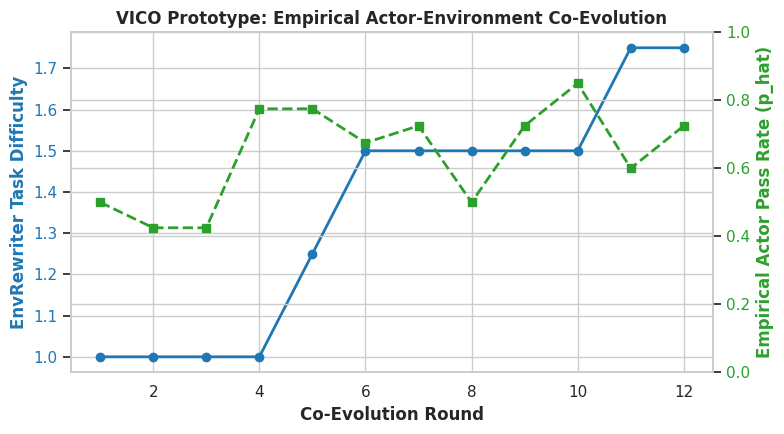

Real VICO Co-Evolution plot saved as vico_coevolution_dynamics.png.


In [16]:
# [CELL 5 - Visualization of Real Co-Evolution Dynamics]

epochs = range(1, rounds + 1)

fig, ax1 = plt.subplots(figsize=(8, 4.5))
sns.set_theme(style="whitegrid")

color = '#1f77b4'
ax1.set_xlabel('Co-Evolution Round', fontweight='bold')
ax1.set_ylabel('EnvRewriter Task Difficulty', color=color, fontweight='bold')
ax1.plot(epochs, difficulty_history, color=color, marker='o', linewidth=2, label='Task Difficulty')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = '#2ca02c'
ax2.set_ylabel('Empirical Actor Pass Rate (p_hat)', color=color, fontweight='bold')
ax2.plot(epochs, pass_history, color=color, marker='s', linestyle='--', linewidth=2, label='Pass Rate (p_hat)')
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(0.0, 1.0)

plt.title('VICO Prototype: Empirical Actor-Environment Co-Evolution', fontweight='bold')
fig.tight_layout()
plt.savefig("vico_coevolution_dynamics.png", dpi=300)
plt.show()

print("Real VICO Co-Evolution plot saved as vico_coevolution_dynamics.png.")